In [113]:
import sys
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    from scipy import stats
    SCIPY_AVAILABLE = True
except Exception:
    SCIPY_AVAILABLE = False

In [114]:
PROJECT_ROOT = Path.home()
DATA_PATH = PROJECT_ROOT / 'presentation' / 'dynamic_supply_chain_logistics_dataset_with_country.csv'
OUTPUT_DIR = PROJECT_ROOT / 'presentation'/ 'output'
OUTPUT_DIR.mkdir(exist_ok=True)
print('Dataset exists:', DATA_PATH.exists())
print('Output folder:', OUTPUT_DIR.resolve())

Dataset exists: True
Output folder: /home/jovyan/presentation/output


In [115]:
df = pd.read_csv(DATA_PATH)
df.head()

,warehouse_inventory_level,handling_equipment_availability,order_fulfillment_status,weather_condition_severity,shipping_costs,supplier_reliability_score,lead_time_days,historical_demand,cargo_condition_status,route_risk_level,customs_clearance_time,disruption_likelihood_score,delay_probability,risk_classification,delivery_time_deviation,product_id,supplier_id,supplier_country
0,985.717,0.481,0.761,0.359,456.504,0.986,2.128,100.773,0.777,1.182,0.502,0.506,0.885,Moderate Risk,9.111,P0353,P0353_S1,Greece
1,985.717,0.481,0.761,0.359,456.504,0.986,2.128,100.773,0.777,1.182,0.502,0.506,0.885,Moderate Risk,9.111,P0353,P0353_S2,South Korea
2,985.717,0.481,0.761,0.359,456.504,0.986,2.128,100.773,0.777,1.182,0.502,0.506,0.885,Moderate Risk,9.111,P0353,P0353_S3,Ethiopia
3,396.700,0.621,0.197,0.231,640.408,0.463,12.608,"5,313.738",0.092,9.612,0.967,0.981,0.544,High Risk,8.175,P0857,P0857_S1,Iran
4,396.700,0.621,0.197,0.231,640.408,0.463,12.608,"5,313.738",0.092,9.612,0.967,0.981,0.544,High Risk,8.175,P0857,P0857_S2,Guatemala


In [116]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 113097 entries, 0 to 113096
Data columns (total 18 columns):
 #   Column                           Non-Null Count   Dtype  
---  ------                           --------------   -----  
 0   warehouse_inventory_level        113097 non-null  float64
 1   handling_equipment_availability  113097 non-null  float64
 2   order_fulfillment_status         113097 non-null  float64
 3   weather_condition_severity       113097 non-null  float64
 4   shipping_costs                   113097 non-null  float64
 5   supplier_reliability_score       113097 non-null  float64
 6   lead_time_days                   113097 non-null  float64
 7   historical_demand                113097 non-null  float64
 8   cargo_condition_status           113097 non-null  float64
 9   route_risk_level                 113097 non-null  float64
 10  customs_clearance_time           113097 non-null  float64
 11  disruption_likelihood_score      113097 non-null  float64
 12  delay_probabi

In [117]:
categorical = ['risk_classification','product_id','supplier_id','supplier_country']

In [118]:
numeric = []

for i in df.keys():
    if i not in categorical:
        numeric.append(i)

print(numeric)

['warehouse_inventory_level', 'handling_equipment_availability', 'order_fulfillment_status', 'weather_condition_severity', 'shipping_costs', 'supplier_reliability_score', 'lead_time_days', 'historical_demand', 'cargo_condition_status', 'route_risk_level', 'customs_clearance_time', 'disruption_likelihood_score', 'delay_probability', 'delivery_time_deviation']


> **Do reliable suppliers deliver better cargo quality upon arrival?.**

In [119]:
required_columns = ['supplier_reliability_score', 'supplier_country','cargo_condition_status']

# 1. Define threshold for High vs. Standard reliability (e.g., score >= 8.0)
threshold = 0.8

high_reliability = df[df['supplier_reliability_score'] >= threshold]['cargo_condition_status']
standard_reliability = df[df['supplier_reliability_score'] < threshold]['cargo_condition_status']

analysis_df = df[required_columns].copy()
print(f"High Reliability Mean Condition Score: {high_reliability.mean():.2f}")
print(f"Standard Reliability Mean Condition Score: {standard_reliability.mean():.2f}")


High Reliability Mean Condition Score: 0.30
Standard Reliability Mean Condition Score: 0.30


In [120]:
target = 'cargo_condition_status'
group_col = 'supplier_tier'
group_a = 'high reliability'
group_b = 'standard reliability'

a = high_reliability
b = standard_reliability

print(f'{group_a}: n = {len(a)}')
print(f'{group_b}: n = {len(b)}')

high reliability: n = 33678
standard reliability: n = 79419


In [121]:
analysis_df['supplier_tier']=np.where(analysis_df['supplier_reliability_score'] >= threshold, group_a, group_b )

In [122]:
comparison_df = analysis_df[[target, group_col]]
summary_stats = analysis_df.groupby(group_col)[target].agg(['count', 'mean', 'median', 'std', 'min', 'max'])
summary_stats

,count,mean,median,std,min,max
supplier_tier,,,,,,
high reliability,33678,0.295,0.153,0.321,0.000,1.000
standard reliability,79419,0.298,0.156,0.322,0.000,1.000


In [123]:
observed_diff = a.mean() - b.mean()

print(f'High Reliability Mean Condition Score: {a.mean():.4f}')
print(f'Standard Reliability Mean Condition Score: {b.mean():.4f}')
print(f'Observed difference ({group_a} - {group_b}): {observed_diff:.4f}')

High Reliability Mean Condition Score: 0.2950
Standard Reliability Mean Condition Score: 0.2982
Observed difference (high reliability - standard reliability): -0.0032


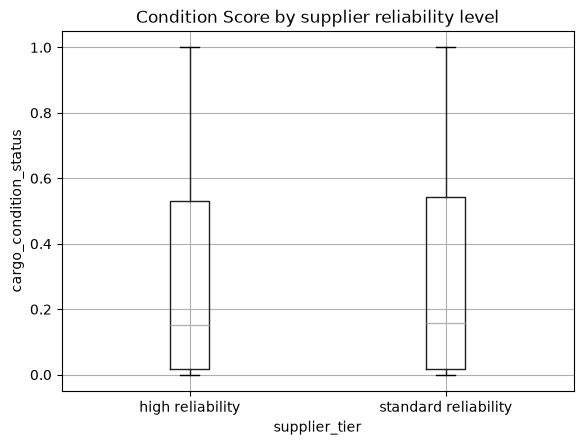

In [124]:
ax = comparison_df.boxplot(column=target, by=group_col)
ax.set_title('Condition Score by supplier reliability level')
ax.set_xlabel('supplier_tier')
ax.set_ylabel('cargo_condition_status')
plt.suptitle('')
plt.show()

In [125]:
t_stat, p_val = stats.ttest_ind(high_reliability, standard_reliability, equal_var=False)
print(f't-statistic: {t_stat:.3f}')
print(f'p-value: {p_val:.4f}')


t-statistic: -1.530
p-value: 0.1259


In [126]:
alpha = 0.05
if p_val < alpha:
    print("\nResult: Reject H0. Reliable suppliers deliver statistically better cargo quality.")
else:
    print("\nResult: Fail to reject H0. The result is not statistically significant at the 5% level.'. No statistically significant difference in cargo quality.")


Result: Fail to reject H0. The result is not statistically significant at the 5% level.'. No statistically significant difference in cargo quality.


 > **Are higher shipping_costs yielding lower delay_probability and better cargo_condition_status**

In [127]:
target = "delivery_time_deviation"

y = df[target]
print("Target:", target)
print("Target summary:")
y.describe()

Target: delivery_time_deviation
Target summary:


count   113,097.000
mean          5.171
std           4.159
min          -2.000
25%           1.260
50%           6.089
75%           9.248
max          10.000
Name: delivery_time_deviation, dtype: float64

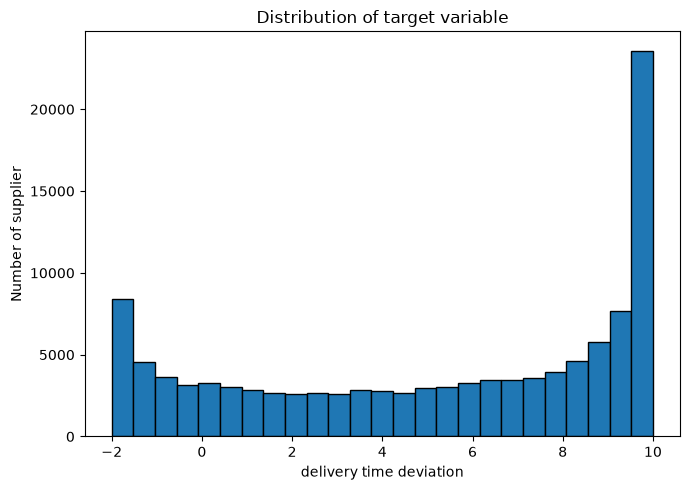

In [128]:
plt.figure(figsize=(7, 5))
plt.hist(y, bins=25, edgecolor="black")
plt.xlabel("delivery time deviation")
plt.ylabel("Number of supplier")
plt.title("Distribution of target variable")
plt.tight_layout()
plt.show()

In [129]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

 > **What is the baseline monetary cost added to shipping for each unit increase in route risk and distance/lead time?**

In [130]:
target = "delivery_time_deviation"
y = df[target]
print("Target:", target)
print("Target summary:")
y.describe()

Target: delivery_time_deviation
Target summary:


count   113,097.000
mean          5.171
std           4.159
min          -2.000
25%           1.260
50%           6.089
75%           9.248
max          10.000
Name: delivery_time_deviation, dtype: float64

In [157]:
core_features = ["disruption_likelihood_score","delay_probability","supplier_reliability_score"]
control_features = ["route_risk_level","lead_time_days", "customs_clearance_time"]
all_features = control_features + core_features
X = df[all_features]
#"route_risk_level", "supplier_reliability_score"
#"disruption_likelihood_score", "customs_clearance_time",

X.head()

,route_risk_level,lead_time_days,customs_clearance_time,disruption_likelihood_score,delay_probability,supplier_reliability_score
0,1.182,2.128,0.502,0.506,0.885,0.986
1,1.182,2.128,0.502,0.506,0.885,0.986
2,1.182,2.128,0.502,0.506,0.885,0.986
3,9.612,12.608,0.967,0.981,0.544,0.463
4,9.612,12.608,0.967,0.981,0.544,0.463


In [158]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
)

print("Training rows:", X_train.shape[0])
print("Test rows:", X_test.shape[0])

Training rows: 84822
Test rows: 28275


In [159]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Model fitted successfully.")

Model fitted successfully.


In [160]:
y_pred = model.predict(X_test)

prediction_preview = pd.DataFrame({
    "actual_deviation": y_test.values,
    "predicted_deviation": y_pred,
    })
prediction_preview["residual"] = prediction_preview["actual_deviation"] - prediction_preview["predicted_deviation"]

prediction_preview.head()

,actual_deviation,predicted_deviation,residual
0,3.362,5.167,-1.806
1,-1.130,5.253,-6.383
2,3.355,5.139,-1.784
3,2.338,5.201,-2.862
4,9.951,5.127,4.825


In [161]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

metrics = pd.DataFrame({
    "metric": ["MAE", "RMSE", "R-squared"],
    "value": [mae, rmse, r2],
})

metrics

,metric,value
0,MAE,3.707
1,RMSE,4.153
2,R-squared,0.000


In [162]:
coefficients = dict(zip(all_features, model.coef_))

print("=== ADJUSTED MONETARY IMPACT (CONTROLLED) ===")
print(f"Baseline delivery_time_deviation (Intercept): {model.intercept_:.2f}\n")

=== ADJUSTED MONETARY IMPACT (CONTROLLED) ===
Baseline delivery_time_deviation (Intercept): 5.14



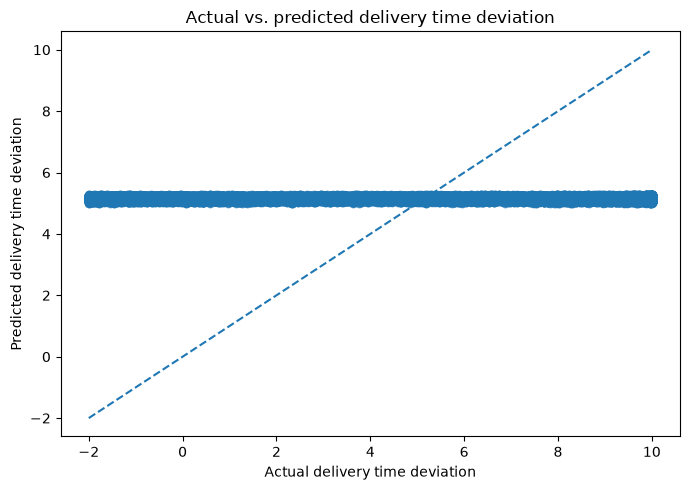

In [163]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, alpha=0.7)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())
plt.plot([min_value, max_value], [min_value, max_value], linestyle="--")

plt.xlabel("Actual delivery time deviation")
plt.ylabel("Predicted delivery time deviation")
plt.title("Actual vs. predicted delivery time deviation")
plt.tight_layout()
plt.show()

The dataset either contains purely random values or lacks the necessary features to predict delivery time delay.

In [166]:


coefficients = model.coef_
intercept = model.intercept_

coef_df = pd.DataFrame({
    "feature": all_features,
    "coefficient": coefficients,
})
coef_df["absolute_coefficient"] = coef_df["coefficient"].abs()
coef_df = coef_df.sort_values("absolute_coefficient", ascending=False)

print(f"Intercept: {intercept:,.2f}")
coef_df

Intercept: 5.14


,feature,coefficient,absolute_coefficient
4,delay_probability,0.081,0.081
3,disruption_likelihood_score,0.033,0.033
5,supplier_reliability_score,0.028,0.028
2,customs_clearance_time,-0.021,0.021
1,lead_time_days,-0.004,0.004
0,route_risk_level,-0.001,0.001
